# Comparisons for Three or More Groups

When comparing **three or more groups**, running many t-tests inflates the false-positive rate. Instead we first run one **omnibus** test that asks: *is there any difference at all among the groups?*

The choice of test depends on:
1. **Independence** – independent groups or repeated measures on the same subjects
2. **Assumptions** – normality and equal variances

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. One-way ANOVA (independent groups)

$$
H_0: \mu_1 = \mu_2 = \dots = \mu_k
$$

$$
F = \frac{MS_{\text{between}}}{MS_{\text{within}}}, \qquad
MS_{\text{between}} = \frac{\sum_{i=1}^k n_i (\bar{X}_i - \bar{X})^2}{k - 1}, \qquad
MS_{\text{within}} = \frac{\sum_{i=1}^k \sum_{j=1}^{n_i} (X_{ij} - \bar{X}_i)^2}{N - k}
$$

If group means are far apart relative to the spread inside each group, $F$ is large and the p-value small.

**Welch's ANOVA** (`oneway.test()`) is the version that does not assume equal variances.

## 2. Repeated-measures ANOVA

Used when the **same subjects** are measured under $k$ conditions. It separates the between-subject variability from the error, which makes it more powerful than a one-way ANOVA on the same data.

## 3. Non-parametric Alternatives

- **Kruskal–Wallis** (independent groups), based on ranks:
$$
H = \frac{12}{N(N+1)} \sum_{i=1}^k \frac{R_i^2}{n_i} - 3(N+1)
$$
- **Friedman** (repeated measures), ranking within each subject:
$$
Q = \frac{12}{n k (k+1)} \sum_{j=1}^k R_j^2 - 3n(k+1)
$$

If an omnibus test is significant ($p < 0.05$), **post-hoc tests** tell us which groups differ (Lesson 17).

## 4. Why Not Just Run Many t-tests?

With $k$ groups there are $\binom{k}{2}$ pairwise tests. If each has a 5% false-positive rate, the chance of **at least one** false positive is $1 - 0.95^m$.

In [2]:
k <- 2:10
m <- choose(k, 2)
fwer <- 1 - 0.95^m
print(data.frame(groups = k, pairwise_tests = m, P_at_least_one_false_positive = round(fwer, 3)),
      row.names = FALSE)

 groups pairwise_tests P_at_least_one_false_positive
      2              1                         0.050
      3              3                         0.143
      4              6                         0.265
      5             10                         0.401
      6             15                         0.537
      7             21                         0.659
      8             28                         0.762
      9             36                         0.842
     10             45                         0.901


## 5. One-way ANOVA and Welch's ANOVA

In [3]:
set.seed(123)
fertilizer <- data.frame(
  yield = c(rnorm(12, 5, 1), rnorm(12, 6, 1), rnorm(12, 7, 1)),
  type  = factor(rep(c("A", "B", "C"), each = 12))
)

anova_result <- aov(yield ~ type, data = fertilizer)
summary(anova_result)

cat("\nWelch's ANOVA (no equal-variance assumption):\n")
oneway.test(yield ~ type, data = fertilizer)

            Df Sum Sq Mean Sq F value   Pr(>F)    
type         2  25.05  12.522   13.97 4.01e-05 ***
Residuals   33  29.57   0.896                     
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


Welch's ANOVA (no equal-variance assumption):



	One-way analysis of means (not assuming equal variances)

data:  yield and type
F = 14.138, num df = 2.00, denom df = 21.98, p-value = 0.0001129


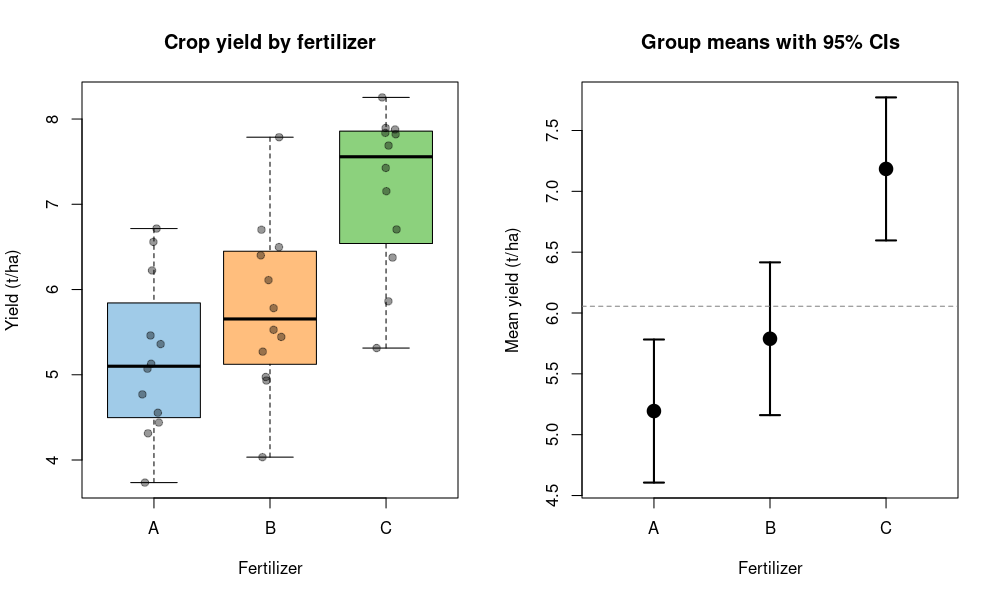

In [4]:
means <- tapply(fertilizer$yield, fertilizer$type, mean)
ses   <- tapply(fertilizer$yield, fertilizer$type, function(x) sd(x) / sqrt(length(x)))

par(mfrow = c(1, 2))
boxplot(yield ~ type, data = fertilizer, col = c("#A0CBE8", "#FFBE7D", "#8CD17D"),
        main = "Crop yield by fertilizer", xlab = "Fertilizer", ylab = "Yield (t/ha)")
stripchart(yield ~ type, data = fertilizer, vertical = TRUE, method = "jitter", pch = 19,
           col = adjustcolor("black", 0.4), add = TRUE)

ci <- qt(0.975, 11) * ses
plot(1:3, means, pch = 19, cex = 1.8, xlim = c(0.5, 3.5), ylim = range(means - ci, means + ci), xaxt = "n",
     main = "Group means with 95% CIs", xlab = "Fertilizer", ylab = "Mean yield (t/ha)")
axis(1, at = 1:3, labels = names(means))
arrows(1:3, means - ci, 1:3, means + ci, angle = 90, code = 3, length = 0.1, lwd = 2)
abline(h = mean(fertilizer$yield), lty = 2, col = "grey50")

## 6. Kruskal–Wallis Test (non-parametric)

In [5]:
set.seed(321)
satisfaction <- data.frame(
  minutes = c(rexp(15, 1/2), rexp(15, 1/3), rexp(15, 1/6)),   # skewed: call-handling times
  store   = factor(rep(c("Store1", "Store2", "Store3"), each = 15))
)
kw_result <- kruskal.test(minutes ~ store, data = satisfaction)
kw_result


	Kruskal-Wallis rank sum test

data:  minutes by store
Kruskal-Wallis chi-squared = 10.667, df = 2, p-value = 0.004826


## 7. Repeated Measures: RM-ANOVA and Friedman

Ten patients each receive three treatments (T1, T2, T3). Patients differ a lot from each other (some always score high), which is exactly the variability repeated-measures designs remove.

In [6]:
if (!suppressMessages(requireNamespace("ez", quietly = TRUE))) install.packages("ez")
suppressMessages(library(ez))

set.seed(42)
n_subj <- 10
subject_effect <- rnorm(n_subj, 0, 3)          # big differences between patients
data_rm <- data.frame(
  subject   = factor(rep(1:n_subj, times = 3)),
  treatment = factor(rep(c("T1", "T2", "T3"), each = n_subj)),
  score     = rep(subject_effect, 3) + rep(c(10, 11, 12), each = n_subj) + rnorm(3 * n_subj, 0, 0.8)
)

ez_result <- ezANOVA(data = data_rm, dv = score, wid = subject, within = treatment)
print(ez_result$ANOVA)

cat("\nFriedman test (non-parametric):\n")
friedman.test(score ~ treatment | subject, data = data_rm)

cat("\nFor comparison - one-way ANOVA that IGNORES the pairing:\n")
summary(aov(score ~ treatment, data = data_rm))

     Effect DFn DFd       F           p p<.05        ges
2 treatment   2  18 8.34665 0.002724219     * 0.08614887



Friedman test (non-parametric):



	Friedman rank sum test

data:  score and treatment and subject
Friedman chi-squared = 8.6, df = 2, p-value = 0.01357



For comparison - one-way ANOVA that IGNORES the pairing:


            Df Sum Sq Mean Sq F value Pr(>F)
treatment    2  16.95   8.476   1.273  0.296
Residuals   27 179.83   6.660               

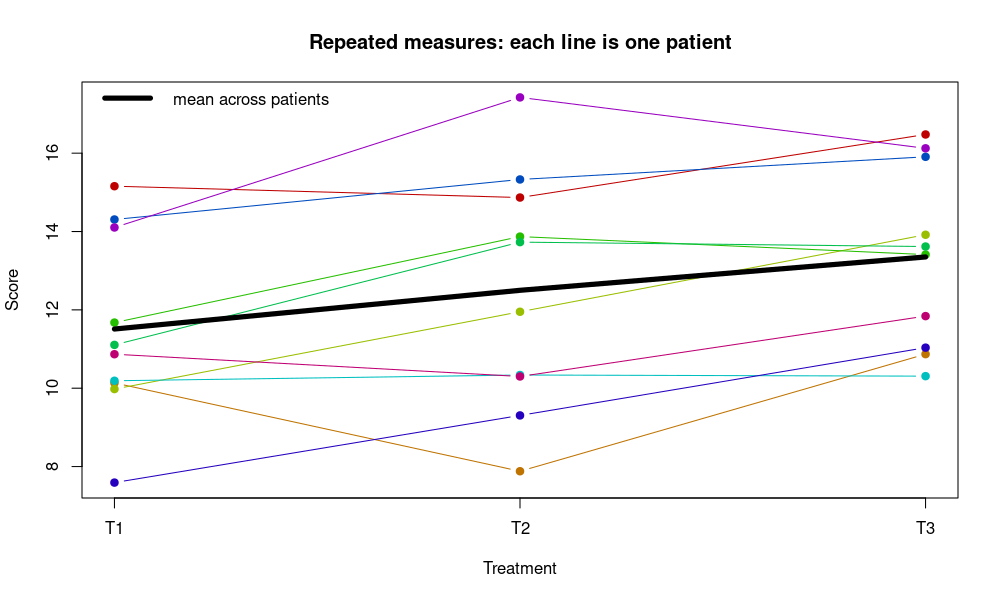

In [7]:
wide <- reshape(data_rm, idvar = "subject", timevar = "treatment", direction = "wide")
mat <- as.matrix(wide[, -1])

matplot(1:3, t(mat), type = "b", lty = 1, pch = 19, col = rainbow(n_subj, v = 0.75), xaxt = "n",
        main = "Repeated measures: each line is one patient", xlab = "Treatment", ylab = "Score")
axis(1, at = 1:3, labels = c("T1", "T2", "T3"))
lines(1:3, colMeans(mat), lwd = 5, col = "black")
legend("topleft", "mean across patients", lwd = 5, bty = "n")

*Insight: Patients sit at very different levels, but nearly every line rises from T1 to T3. The repeated-measures ANOVA and the Friedman test pick this up clearly. The one-way ANOVA ignores who is who, sees mostly between-patient noise, and is far less sensitive.*

## Real-World Use Case or Analogy

- **One-way ANOVA**: compare the average yield of **three different fertilizer types**.
- **Welch's ANOVA**: the same, when one fertilizer gives much more variable results.
- **Repeated-measures ANOVA**: test the same patients' blood pressure at **three time points**.
- **Kruskal–Wallis**: compare skewed customer waiting times between **three stores**.
- **Friedman test**: compare several algorithms on the **same benchmark datasets**, ranking them within each dataset.

ANOVA is like a **smoke detector**: it tells you there's a fire somewhere in the building (some groups differ), but not which room. Post-hoc tests (Lesson 17) are the firefighters checking room by room.